┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


Reference state -> qubit=20, index=32, F=0.9511713662412458 (threshold=0.95)


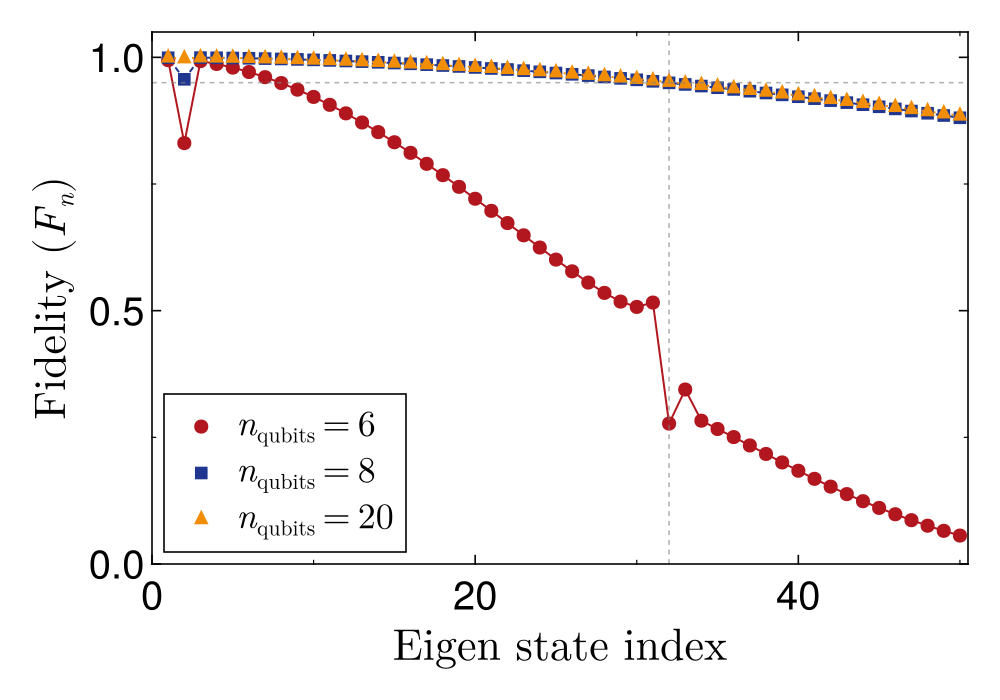

In [ ]:
using JLD2, CairoMakie, LinearAlgebra

@load "Fidelity_Analytic_AllQubits.jld2" F_data qubit_list num_states
qubit_list = [6, 8, 20]

CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        xlabelsize = 22,
        ylabelsize = 22,
        titlesize = 22,
        xticklabelsize = 20,
        yticklabelsize = 20,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = true,
        yminorticksvisible = true,
        xminortickwidth = 0.6,
        yminortickwidth = 0.6,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xticklabelpad = 3,
        yticklabelpad = 3,
		xtickalign = 1,
		ytickalign = 1,
		xminortickalign = 1,
		yminortickalign = 1,
		xticksmirrored = true,
		yticksmirrored = true,
    ),
))

fig = Figure(resolution = (500, 350), backgroundcolor = :white)

ax = Axis(fig[1,1],
    xlabel = L"Eigen state index$$",
    ylabel = L"Fidelity $(F_n)$",
    limits = (0, num_states + 0.5, 0, 1.05),
)

palette  = [
	RGBf(0.698, 0.090, 0.122),
	RGBf(0.122, 0.216, 0.569),
    RGBf(0.949, 0.557, 0.024),
]
markers  = [:circle, :rect, :utriangle]
linesty  = [:solid, :dash, :dot]
handles  = []

for (i, q) in enumerate(qubit_list)
    x = 1:num_states
    y = F_data[q]
    l = lines!(ax, x, y; color = palette[i], linewidth = 1.0, linestyle = linesty[i])
    sct = scatter!(ax, x, y; color = palette[i], marker = markers[i], markersize = 10, strokewidth = 0)
    push!(handles, sct)
end


# ---- Controls ----
fidelity_threshold = 0.95
threshold_qubit    = 20          # key into F_data used to determine the threshold state
line_color         = (:grey, 0.6)
line_width         = 0.8
line_style         = :dash
label_fontsize     = 18
label_color        = :black

# ---- Validate inputs ----
if !haskey(F_data, threshold_qubit)
    error("threshold_qubit = $threshold_qubit not found in F_data. Available keys: $(collect(keys(F_data)))")
end

y_ref = F_data[threshold_qubit]
@assert length(y_ref) == num_states "F_data[$threshold_qubit] length ($(length(y_ref))) does not match num_states ($num_states)"

idx_candidates = findall(y_ref .> fidelity_threshold)

if isempty(idx_candidates)
    @warn "No eigenstate exceeds fidelity_threshold=$fidelity_threshold for qubit=$threshold_qubit. Skipping reference lines/labels."
else
    # Index of the state with the MINIMUM fidelity among those above threshold
    min_idx = idx_candidates[argmin(y_ref[idx_candidates])]
    min_F   = y_ref[min_idx]

    println("Reference state -> qubit=$threshold_qubit, index=$min_idx, F=$min_F (threshold=$fidelity_threshold)")

    # ---- Draw thin grey reference lines ----
    hlines!(ax, [fidelity_threshold]; color = line_color, linewidth = line_width, linestyle = line_style)
    vlines!(ax, [min_idx];            color = line_color, linewidth = line_width, linestyle = line_style)

end


axislegend(ax,
    handles,
    [L"$n_\mathrm{qubits} = 6$", L"$n_\mathrm{qubits} = 8$", L"$n_\mathrm{qubits} = 20$"],
    position = :lb,
    framevisible = true,
    framewidth = 0.8,
    labelsize = 18,
    labelfont = "Times New Roman",
    patchsize = (25, 10),
    padding = (6, 6, 6, 6),
)

save("Fidelity_Analytic_AllQubits_PRL2.pdf", fig)
fig